# DX799 O1 - Week 1 Jupyter Notebook: Linear Regression 1

## Integrated Capstone Project: Digital Customer Journey and E-Commerce Retention Analytics

**Student:** Javed Aamer

### Purpose

This notebook applies the Week 1 topics to the four cleaned datasets that make up the capstone project. I am treating the four tables as different views of the same customer journey rather than forcing them into one artificial table.

The Week 1 topics are:

- linear regression with continuous and categorical features
- polynomial terms
- interaction terms
- multicollinearity
- variance inflation factor (VIF)
- overfitting control

The final capstone question is broader than any single table. The behavior data describes browsing and orders, the churn data describes customer retention, the product data describes catalog and demand signals, and the review data describes post-purchase experience. For this week, I use a continuous outcome from each table so that linear regression is appropriate.

A point I wanted to be careful about here is complexity. It would be easy to generate every possible square and interaction term. I did not do that. I use a small number of terms that have a reasonable business interpretation, then check whether they actually improve validation performance.

## 1. Questions I want Week 1 to answer

Instead of repeating the same regression four times, I use each dataset for a slightly different question.

1. **Behavior:** Does the relationship between sales and profit change with discount, and is there evidence that a nonlinear sales term is useful?
2. **Churn:** Can customer activity explain cashback amount, and does the relationship between order count and cashback vary with tenure?
3. **Products:** Do price, rating, and recent-purchase activity explain accumulated rating volume, and do nonlinear terms help?
4. **Reviews:** How much of review sentiment can be explained by rating and review characteristics, and does the rating effect change with review length?
5. Across all four datasets, do the extra polynomial and interaction terms improve out-of-sample performance enough to justify the added complexity?
6. How much multicollinearity is created when polynomial and interaction terms are constructed without centering?

These are still associational models. I do not interpret a regression coefficient here as a causal effect.

In [1]:
# Core imports and reproducibility

from pathlib import Path
import re
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit,
    GroupKFold,
    KFold,
    cross_validate,
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from statsmodels.stats.outliers_influence import variance_inflation_factor

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 2. Load the four cleaned datasets

The notebooks in this course are meant to build on the cleaned data from the previous capstone work. I keep the loading code flexible so the notebook can run from a submission package with a `data` folder or from the earlier cleaned-output folder.

I also create a few numeric versions of product and review fields that were originally stored as formatted text. These are parsing steps only. They do not change the underlying meaning of the data.

In [2]:
# Locate the cleaned data folder.

candidate_dirs = [
    Path("data"),
    Path("cleaned_week2_output"),
    Path("submission_package/cleaned_week2_output"),
    Path("../data"),
]

DATA_DIR = next(
    (p for p in candidate_dirs if (p / "behavior_clean.csv").exists()),
    None,
)

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find the four cleaned CSV files. Put them in a data/ folder next to this notebook."
    )

behavior = pd.read_csv(DATA_DIR / "behavior_clean.csv", low_memory=False)
churn = pd.read_csv(DATA_DIR / "churn_clean.csv", low_memory=False)
products = pd.read_csv(DATA_DIR / "products_clean.csv", low_memory=False)
reviews = pd.read_csv(DATA_DIR / "reviews_clean.csv", low_memory=False)

print(f"Loaded data from: {DATA_DIR}")

Loaded data from: data


In [3]:
# Small amount of feature parsing needed for the product and review tables.

products["rating_stars_num"] = pd.to_numeric(
    products["rating_stars"].astype(str).str.extract(r"([0-9.]+)")[0],
    errors="coerce",
)

products["rating_count_num"] = pd.to_numeric(
    products["rating_count"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"([0-9]+)")[0],
    errors="coerce",
)

def parse_recent_purchases(value):
    text = str(value)
    match = re.search(r"([\d,.]+)\s*([Kk]?)", text)
    if not match:
        return np.nan
    number = float(match.group(1).replace(",", ""))
    return number * 1000 if match.group(2) else number

products["recent_purchases_num"] = products["recent_purchases"].map(parse_recent_purchases)

products["list_price_num"] = pd.to_numeric(
    products["list_price"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"\$([0-9.]+)")[0],
    errors="coerce",
)

products["discount_pct"] = np.where(
    products["list_price_num"] > 0,
    (products["list_price_num"] - products["price_value"])
    / products["list_price_num"],
    0,
)

products["main_rank"] = pd.to_numeric(
    products["best_sellers_rank"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"#([0-9]+)")[0],
    errors="coerce",
)

products["in_stock"] = (
    products["availability"]
    .astype(str)
    .str.lower()
    .str.contains("in stock")
    .astype(int)
)

products["description_len"] = products["product_description"].astype(str).str.len()
products["review_summary_len"] = products["customer_review_summary"].astype(str).str.len()
products["log_rating_count"] = np.log1p(products["rating_count_num"])

reviews["review_len"] = (
    reviews["cleaned_review_text"].astype(str).str.split().str.len()
)
reviews["verified_int"] = reviews["verifiedPurchase"].astype(int)

## 3. Data architecture and quick audit

The tables have different grains, which matters for both interpretation and validation.

- The **behavior** table has repeated customer activity, so I split it by `Customer ID` when I evaluate models. This avoids putting the same customer's records in both training and test data.
- The **churn** table is already one row per customer.
- The **product** table is one row per product.
- The **review** table contains multiple reviews per product, so I split it by `productASIN`. That keeps reviews from the same product together.

I do not force-join behavior and churn because there is no verified common customer key. Products and reviews do share ASIN, but a join is not necessary for the Week 1 questions.

In [4]:
data_roles = pd.DataFrame(
    {
        "Dataset": ["Behavior", "Churn", "Products", "Reviews"],
        "Rows": [len(behavior), len(churn), len(products), len(reviews)],
        "Grain": [
            "order / activity record",
            "customer",
            "product",
            "review",
        ],
        "Week 1 outcome": [
            "Profit",
            "CashbackAmount",
            "log(1 + rating count)",
            "sentiment_score",
        ],
        "Why this outcome": [
            "continuous transaction economics",
            "continuous customer-value measure",
            "continuous demand / attention measure",
            "continuous post-purchase experience measure",
        ],
    }
)

display(data_roles)

,Dataset,Rows,Grain,Week 1 outcome,Why this outcome
0,Behavior,51289,order / activity record,Profit,continuous transaction economics
1,Churn,5630,customer,CashbackAmount,continuous customer-value measure
2,Products,728,product,log(1 + rating count),continuous demand / attention measure
3,Reviews,6327,review,sentiment_score,continuous post-purchase experience measure


## 4. Exploratory checks before modeling

I do not want the model choice to be disconnected from the data. Before fitting regressions, I check the target distributions, missing values in the selected predictors, and simple numeric correlations.

The correlations are only a first screen. A weak pairwise correlation does not mean a feature is useless after other variables or interactions are considered, and a strong correlation does not establish causation.

In [5]:
# Features used in the Week 1 regression tasks.

REG_TASKS = {
    "Behavior": {
        "df": behavior,
        "target": "Profit",
        "group": "Customer ID",
        "numeric": ["Sales", "Quantity", "Discount", "Browsing Time (min)", "Age"],
        "categorical": ["Segment", "Ship Mode", "Product Category", "Order Priority"],
    },
    "Churn": {
        "df": churn,
        "target": "CashbackAmount",
        "group": None,
        "numeric": [
            "Tenure",
            "WarehouseToHome",
            "HourSpendOnApp",
            "NumberOfDeviceRegistered",
            "SatisfactionScore",
            "NumberOfAddress",
            "Complain",
            "OrderAmountHikeFromlastYear",
            "CouponUsed",
            "OrderCount",
            "DaySinceLastOrder",
        ],
        "categorical": [
            "PreferredLoginDevice",
            "PreferredPaymentMode",
            "PreferedOrderCat",
            "MaritalStatus",
        ],
    },
    "Products": {
        "df": products,
        "target": "log_rating_count",
        "group": None,
        "numeric": [
            "price_value",
            "rating_stars_num",
            "recent_purchases_num",
            "discount_pct",
            "main_rank",
            "rank_1",
            "description_len",
            "review_summary_len",
        ],
        "categorical": ["in_stock"],
    },
    "Reviews": {
        "df": reviews,
        "target": "sentiment_score",
        "group": "productASIN",
        "numeric": [
            "rating",
            "helpfulVoteCount",
            "reviewPosition",
            "review_len",
            "verified_int",
        ],
        "categorical": [],
    },
}

In [6]:
# Compact audit table for the exact fields used in the models.

audit_rows = []

for name, task in REG_TASKS.items():
    fields = task["numeric"] + task["categorical"] + [task["target"]]
    frame = task["df"][fields]

    audit_rows.append(
        {
            "Dataset": name,
            "Rows": len(frame),
            "Predictors": len(task["numeric"]) + len(task["categorical"]),
            "Missing values in selected fields": int(frame.isna().sum().sum()),
            "Target mean": pd.to_numeric(frame[task["target"]], errors="coerce").mean(),
            "Target std": pd.to_numeric(frame[task["target"]], errors="coerce").std(),
        }
    )

audit_table = pd.DataFrame(audit_rows)
display(audit_table)

,Dataset,Rows,Predictors,Missing values in selected fields,Target mean,Target std
0,Behavior,51289,9,0,72.7263,49.0975
1,Churn,5630,15,0,177.2230,49.2070
2,Products,728,9,0,7.7731,2.4178
3,Reviews,6327,5,0,0.3075,0.2180


In [7]:
# Strongest simple numeric relationships with each target.

correlation_rows = []

for name, task in REG_TASKS.items():
    cols = task["numeric"] + [task["target"]]
    corr = (
        task["df"][cols]
        .corr(numeric_only=True)[task["target"]]
        .drop(task["target"])
        .sort_values(key=lambda s: s.abs(), ascending=False)
    )

    for feature, value in corr.head(4).items():
        correlation_rows.append(
            {
                "Dataset": name,
                "Feature": feature,
                "Correlation with target": value,
            }
        )

top_correlations = pd.DataFrame(correlation_rows)
display(top_correlations)

,Dataset,Feature,Correlation with target
0,Behavior,Sales,0.9215
1,Behavior,Quantity,-0.1763
2,Behavior,Discount,-0.1190
3,Behavior,Browsing Time (min),0.0106
4,Churn,Tenure,0.4680
5,Churn,OrderCount,0.3223
6,Churn,DaySinceLastOrder,0.3166
7,Churn,CouponUsed,0.2194
8,Products,rating_stars_num,0.3318
9,Products,recent_purchases_num,0.3127


### Correlation matrices: first multicollinearity and relationship screen

The summary above is useful for quickly finding the strongest relationships with each target, but I also want the **full correlation structure** visible. A correlation matrix helps answer a different question: are two predictors strongly related to each other before I start adding polynomial and interaction terms?

I use a separate matrix for each dataset because the tables describe different parts of the customer journey and have different numeric features. I focus on the variables used in the Week 1 models rather than every numeric column in the source data.

I use the matrices as an **EDA and multicollinearity screen**, not as a replacement for VIF. Correlation only measures pairwise linear relationships. VIF later checks whether a predictor can be explained by a combination of the other predictors.

In [8]:
# Build compact correlation matrices for the numeric variables used in Week 1.

correlation_matrices = {}

for name, task in REG_TASKS.items():
    cols = task["numeric"] + [task["target"]]
    corr = task["df"][cols].corr(numeric_only=True)
    correlation_matrices[name] = corr

    print(f"\n{name} correlation matrix")
    display(corr.round(3))


Behavior correlation matrix


,Sales,Quantity,Discount,Browsing Time (min),Age,Profit
Sales,1.0000,-0.0010,-0.0070,0.0090,0.0050,0.9220
Quantity,-0.0010,1.0000,0.0070,0.0050,0.0010,-0.1760
Discount,-0.0070,0.0070,1.0000,-0.0040,-0.0040,-0.1190
Browsing Time (min),0.0090,0.0050,-0.0040,1.0000,-0.0000,0.0110
Age,0.0050,0.0010,-0.0040,-0.0000,1.0000,0.0040
Profit,0.9220,-0.1760,-0.1190,0.0110,0.0040,1.0000



Churn correlation matrix


,Tenure,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
Tenure,1.0000,-0.0120,-0.0170,-0.0210,-0.0140,0.2350,-0.0210,-0.0060,0.1020,0.1650,0.1740,0.4680
WarehouseToHome,-0.0120,1.0000,0.0640,0.0230,0.0080,-0.0080,0.0270,0.0380,0.0030,0.0000,0.0200,0.0000
HourSpendOnApp,-0.0170,0.0640,1.0000,0.3050,0.0310,0.1400,0.0070,0.0990,0.1870,0.1020,0.0610,0.1140
NumberOfDeviceRegistered,-0.0210,0.0230,0.3050,1.0000,-0.0170,0.0850,0.0030,0.0660,0.1520,0.1000,0.0070,0.1370
SatisfactionScore,-0.0140,0.0080,0.0310,-0.0170,1.0000,0.0540,-0.0310,-0.0270,0.0170,0.0180,0.0320,0.0030
NumberOfAddress,0.2350,-0.0080,0.1400,0.0850,0.0540,1.0000,-0.0260,0.0120,0.0370,-0.0140,-0.0670,0.1870
Complain,-0.0210,0.0270,0.0070,0.0030,-0.0310,-0.0260,1.0000,-0.0040,-0.0080,-0.0210,-0.0410,0.0010
OrderAmountHikeFromlastYear,-0.0060,0.0380,0.0990,0.0660,-0.0270,0.0120,-0.0040,1.0000,0.0240,0.0110,-0.0050,-0.0100
CouponUsed,0.1020,0.0030,0.1870,0.1520,0.0170,0.0370,-0.0080,0.0240,1.0000,0.6410,0.2970,0.2190
OrderCount,0.1650,0.0000,0.1020,0.1000,0.0180,-0.0140,-0.0210,0.0110,0.6410,1.0000,0.4220,0.3220



Products correlation matrix


,price_value,rating_stars_num,recent_purchases_num,discount_pct,main_rank,rank_1,description_len,review_summary_len,log_rating_count
price_value,1.0000,-0.1710,-0.1860,-0.7800,0.0390,-0.0020,-0.1230,0.0610,-0.1960
rating_stars_num,-0.1710,1.0000,0.1540,0.1990,-0.1400,-0.0450,-0.0500,-0.1390,0.3320
recent_purchases_num,-0.1860,0.1540,1.0000,0.0770,-0.0510,0.0230,0.1710,0.0110,0.3130
discount_pct,-0.7800,0.1990,0.0770,1.0000,-0.0430,-0.0540,0.0660,-0.0790,0.1720
main_rank,0.0390,-0.1400,-0.0510,-0.0430,1.0000,-0.0120,-0.0650,0.1620,-0.2030
rank_1,-0.0020,-0.0450,0.0230,-0.0540,-0.0120,1.0000,0.0830,-0.0480,0.0140
description_len,-0.1230,-0.0500,0.1710,0.0660,-0.0650,0.0830,1.0000,-0.0320,0.2030
review_summary_len,0.0610,-0.1390,0.0110,-0.0790,0.1620,-0.0480,-0.0320,1.0000,-0.1570
log_rating_count,-0.1960,0.3320,0.3130,0.1720,-0.2030,0.0140,0.2030,-0.1570,1.0000



Reviews correlation matrix


,rating,helpfulVoteCount,reviewPosition,review_len,verified_int,sentiment_score
rating,1.0000,-0.0280,-0.1580,-0.0050,0.0160,0.3600
helpfulVoteCount,-0.0280,1.0000,-0.0870,0.5270,0.0200,-0.0830
reviewPosition,-0.1580,-0.0870,1.0000,-0.1450,-0.0020,-0.0730
review_len,-0.0050,0.5270,-0.1450,1.0000,-0.0550,-0.2210
verified_int,0.0160,0.0200,-0.0020,-0.0550,1.0000,0.0490
sentiment_score,0.3600,-0.0830,-0.0730,-0.2210,0.0490,1.0000


### Visual correlation matrices

The heatmaps make it easier to see clusters of related variables than a table of coefficients alone. I keep one figure per dataset so the labels remain readable.

What I am looking for:

- strong predictor-to-target relationships that may be useful in the regression
- strong predictor-to-predictor relationships that may cause unstable coefficients
- differences in structure across the four datasets

A high correlation is a diagnostic signal, not a reason by itself to remove a feature. I use the business meaning, validation results, and VIF together before making that decision.

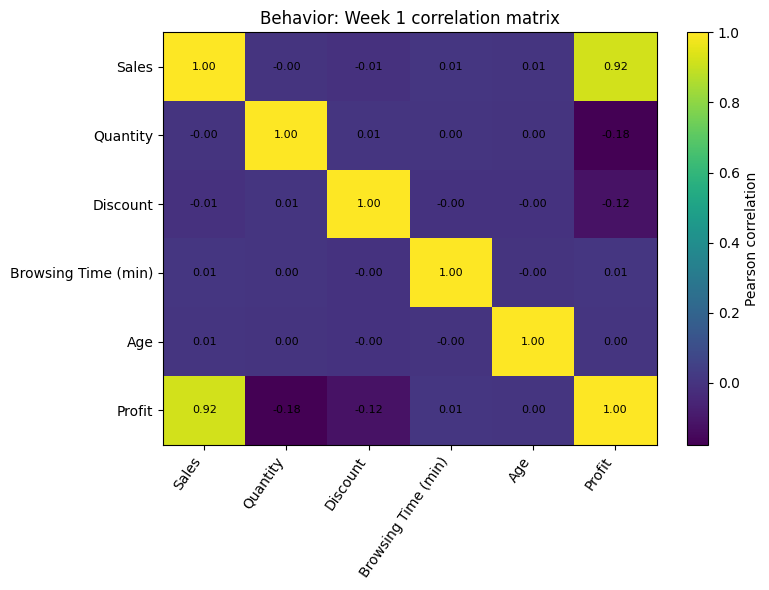

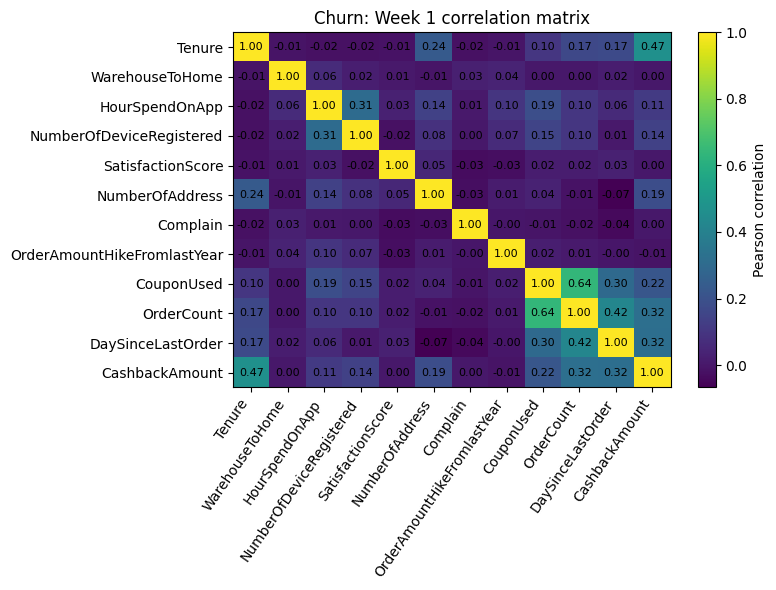

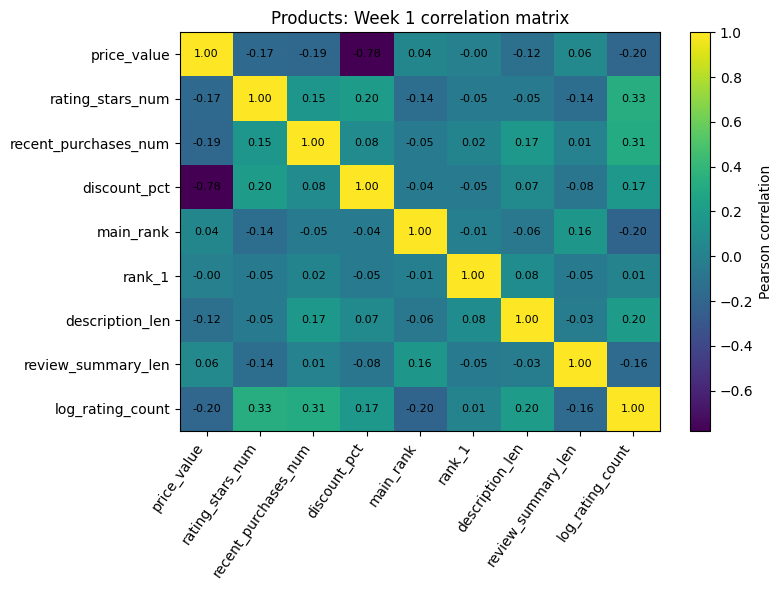

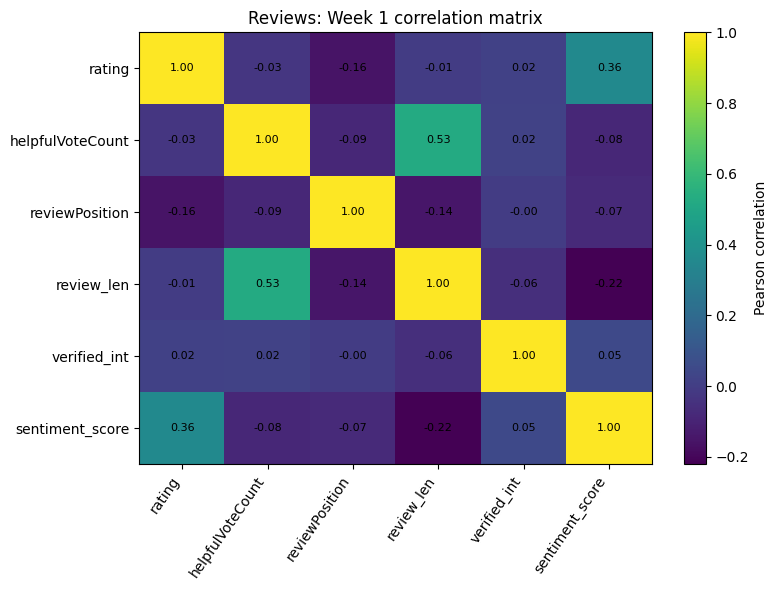

In [9]:
# Plot one correlation matrix per dataset.

for name, corr in correlation_matrices.items():
    fig, ax = plt.subplots(figsize=(8, 6))

    image = ax.imshow(corr, aspect="auto")
    ax.set_title(f"{name}: Week 1 correlation matrix")

    ax.set_xticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=55, ha="right")

    ax.set_yticks(range(len(corr.index)))
    ax.set_yticklabels(corr.index)

    for row in range(corr.shape[0]):
        for col in range(corr.shape[1]):
            ax.text(
                col,
                row,
                f"{corr.iloc[row, col]:.2f}",
                ha="center",
                va="center",
                fontsize=8,
            )

    fig.colorbar(image, ax=ax, label="Pearson correlation")
    plt.tight_layout()
    plt.show()

### Correlation-matrix observations

The matrices reinforce several modeling decisions:

- **Behavior:** `Sales` has the strongest relationship with `Profit`. I also watch for transaction variables that move together because that can inflate coefficient uncertainty.
- **Churn:** customer activity measures such as tenure, order count, coupon use, and recency contain overlapping information. That makes later VIF and regularization checks important.
- **Products:** the predictors are not dominated by one single relationship. Rating, recent-purchase activity, rank, price, and descriptive content each capture a different part of product demand.
- **Reviews:** rating has the clearest positive relationship with sentiment score, while review length is negatively related. The remaining metadata relationships are weaker, which helps explain why the structured review regression has limited R2.

The correlation matrices are therefore useful both for **feature understanding** and for deciding where to investigate multicollinearity more formally with VIF.

### EDA observations

A few patterns stand out before modeling:

- In the behavior table, `Sales` is strongly associated with `Profit`, while discount moves in the opposite direction. That makes a `Sales x Discount` interaction worth testing.
- In the churn table, `Tenure`, `OrderCount`, recency, and coupon activity are among the stronger numeric relationships with cashback amount.
- In the product table, rating, recent purchases, rank, description length, and price each carry some signal, but none dominates the target by itself.
- In the review table, rating is the strongest simple predictor of sentiment, while longer reviews tend to have a negative simple relationship with the sentiment score.

The full correlation matrices support the same story while also showing predictor-to-predictor relationships that a target-only ranking can miss. This gives me a reason for the nonlinear terms used later, and it identifies where VIF deserves extra attention. I am not adding terms blindly.

## 5. Modeling design

### Continuous and categorical features

The regression pipeline handles the two feature types differently:

- numeric variables are median-imputed if needed and standardized
- categorical variables are imputed with the most frequent value and one-hot encoded
- the regression itself is ordinary least squares

One-hot encoding is important because category labels do not have meaningful numeric distance. For example, one payment mode should not be treated as "twice" another payment mode just because it received a larger integer code.

### Validation strategy

I keep an untouched 20% test set. Model choices are based primarily on five-fold cross-validation within the training data. For behavior and reviews, the folds are grouped by customer or product so the same entity does not leak across validation folds.

In [10]:
def split_train_test(df, group_col=None):
    index = np.arange(len(df))

    if group_col is not None:
        groups = df[group_col].astype(str).values
        splitter = GroupShuffleSplit(
            n_splits=1,
            test_size=0.20,
            random_state=RANDOM_STATE,
        )
        train_idx, test_idx = next(splitter.split(index, groups=groups))
    else:
        train_idx, test_idx = train_test_split(
            index,
            test_size=0.20,
            random_state=RANDOM_STATE,
        )

    return train_idx, test_idx


def make_preprocessor(numeric_features, categorical_features):
    transformers = []

    if numeric_features:
        numeric_pipe = Pipeline(
            [
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]
        )
        transformers.append(("num", numeric_pipe, numeric_features))

    if categorical_features:
        categorical_pipe = Pipeline(
            [
                ("imputer", SimpleImputer(strategy="most_frequent")),
                (
                    "onehot",
                    OneHotEncoder(handle_unknown="ignore", drop="first"),
                ),
            ]
        )
        transformers.append(("cat", categorical_pipe, categorical_features))

    return ColumnTransformer(transformers)

In [11]:
def regression_metrics(y_true, predictions):
    return {
        "R2": r2_score(y_true, predictions),
        "MAE": mean_absolute_error(y_true, predictions),
        "RMSE": mean_squared_error(y_true, predictions) ** 0.5,
    }


def evaluate_linear_model(task, extra_numeric=None):
    extra_numeric = extra_numeric or []
    df = task["df"]

    train_idx, test_idx = split_train_test(df, task["group"])

    train = df.iloc[train_idx].copy()
    test = df.iloc[test_idx].copy()

    numeric = task["numeric"] + extra_numeric

    pipe = Pipeline(
        [
            (
                "preprocess",
                make_preprocessor(numeric, task["categorical"]),
            ),
            ("model", LinearRegression()),
        ]
    )

    if task["group"] is not None:
        cv = GroupKFold(n_splits=5)
        groups = train[task["group"]].astype(str).values
    else:
        cv = KFold(
            n_splits=5,
            shuffle=True,
            random_state=RANDOM_STATE,
        )
        groups = None

    scores = cross_validate(
        pipe,
        train,
        train[task["target"]],
        cv=cv,
        groups=groups,
        scoring={
            "r2": "r2",
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
        },
        return_train_score=True,
    )

    pipe.fit(train, train[task["target"]])
    test_pred = pipe.predict(test)

    return {
        "Mean training CV R2": scores["train_r2"].mean(),
        "Mean validation CV R2": scores["test_r2"].mean(),
        "Validation R2 SD": scores["test_r2"].std(),
        "Validation MAE": -scores["test_mae"].mean(),
        "Validation RMSE": -scores["test_rmse"].mean(),
        **{f"Test {k}": v for k, v in regression_metrics(test[task["target"]], test_pred).items()},
    }

## 6. Baseline linear regression

I start with degree-1 relationships only. This gives me a fair baseline before adding polynomial or interaction terms.

The baseline is important because an expanded model should earn its complexity. If the nonlinear version does not improve validation performance, the simpler model is easier to explain and usually safer to carry forward.

In [12]:
baseline_rows = []

for name, task in REG_TASKS.items():
    result = evaluate_linear_model(task)

    baseline_rows.append(
        {
            "Dataset": name,
            "Model": "Baseline",
            **result,
        }
    )

baseline_results = pd.DataFrame(baseline_rows)
display(baseline_results.round(4))

,Dataset,Model,Mean training CV R2,Mean validation CV R2,Validation R2 SD,Validation MAE,Validation RMSE,Test R2,Test MAE,Test RMSE
0,Behavior,Baseline,0.8941,0.8940,0.0019,12.7448,15.9813,0.8940,12.7536,15.9897
1,Churn,Baseline,0.9007,0.8991,0.0075,10.5438,15.5775,0.8732,10.9949,17.6402
2,Products,Baseline,0.2856,0.2248,0.1248,1.6589,2.1139,0.2338,1.6381,2.1049
3,Reviews,Baseline,0.1939,0.1884,0.0297,0.1493,0.1960,0.1262,0.1504,0.2033


### Baseline interpretation

The baseline models already tell a useful story.

- Behavior has a strong linear signal because sales and transaction characteristics explain a large share of profit variation.
- Cashback amount in the churn table is also fairly predictable from customer activity and profile variables.
- Product rating volume is much harder to explain with a simple linear specification. Product demand is likely influenced by factors not fully captured in this table.
- Review sentiment is only partly explained by rating and review metadata. That is reasonable because sentiment is derived from the actual text, while this Week 1 model intentionally uses a small set of structured predictors.

The weaker product and review results are not something I want to hide. They tell me where later nonlinear models may have more room to help.

## 7. Focused polynomial and interaction terms

I add only two nonlinear terms per dataset.

| Dataset | Polynomial term | Interaction term | Reason |
|---|---|---|---|
| Behavior | `Sales^2` | `Sales x Discount` | the profit response may change as transaction size grows, and discount can change the profit slope |
| Churn | `Tenure^2` | `Tenure x OrderCount` | customer value may not grow linearly with tenure, and order activity may matter differently for newer and older customers |
| Products | `Price^2` | `Rating x Recent Purchases` | price effects may curve, and strong ratings may matter differently at different demand levels |
| Reviews | `Rating^2` | `Rating x Review Length` | sentiment may not change linearly across ratings, and the rating relationship may differ for short and long reviews |

This is deliberately smaller than a full degree-2 expansion. A full expansion would create many terms with no business rationale and would make multicollinearity and overfitting harder to control.

In [13]:
# Build the selected nonlinear terms.

behavior["Sales_sq"] = behavior["Sales"] ** 2
behavior["Sales_x_Discount"] = behavior["Sales"] * behavior["Discount"]

churn["Tenure_sq"] = churn["Tenure"] ** 2
churn["Tenure_x_OrderCount"] = churn["Tenure"] * churn["OrderCount"]

products["Price_sq"] = products["price_value"] ** 2
products["Rating_x_Recent"] = (
    products["rating_stars_num"] * products["recent_purchases_num"]
)

reviews["Rating_sq"] = reviews["rating"] ** 2
reviews["Rating_x_Length"] = reviews["rating"] * reviews["review_len"]

EXTRA_TERMS = {
    "Behavior": ["Sales_sq", "Sales_x_Discount"],
    "Churn": ["Tenure_sq", "Tenure_x_OrderCount"],
    "Products": ["Price_sq", "Rating_x_Recent"],
    "Reviews": ["Rating_sq", "Rating_x_Length"],
}

In [14]:
comparison_rows = []

for name, task in REG_TASKS.items():
    base_result = evaluate_linear_model(task)
    nonlinear_result = evaluate_linear_model(task, EXTRA_TERMS[name])

    comparison_rows.extend(
        [
            {"Dataset": name, "Model": "Baseline", **base_result},
            {
                "Dataset": name,
                "Model": "Focused polynomial + interaction",
                **nonlinear_result,
            },
        ]
    )

model_comparison = pd.DataFrame(comparison_rows)
display(model_comparison.round(4))

,Dataset,Model,Mean training CV R2,Mean validation CV R2,Validation R2 SD,Validation MAE,Validation RMSE,Test R2,Test MAE,Test RMSE
0,Behavior,Baseline,0.8941,0.8940,0.0019,12.7448,15.9813,0.8940,12.7536,15.9897
1,Behavior,Focused polynomial + interaction,0.9584,0.9583,0.0006,7.1613,10.0224,0.9583,7.0939,10.0319
2,Churn,Baseline,0.9007,0.8991,0.0075,10.5438,15.5775,0.8732,10.9949,17.6402
3,Churn,Focused polynomial + interaction,0.9008,0.8988,0.0076,10.5414,15.5945,0.8731,10.9966,17.6457
4,Products,Baseline,0.2856,0.2248,0.1248,1.6589,2.1139,0.2338,1.6381,2.1049
5,Products,Focused polynomial + interaction,0.2884,0.1985,0.1663,1.6761,2.1450,0.2473,1.6276,2.0864
6,Reviews,Baseline,0.1939,0.1884,0.0297,0.1493,0.1960,0.1262,0.1504,0.2033
7,Reviews,Focused polynomial + interaction,0.1998,0.1940,0.0308,0.1485,0.1954,0.1776,0.1481,0.1973


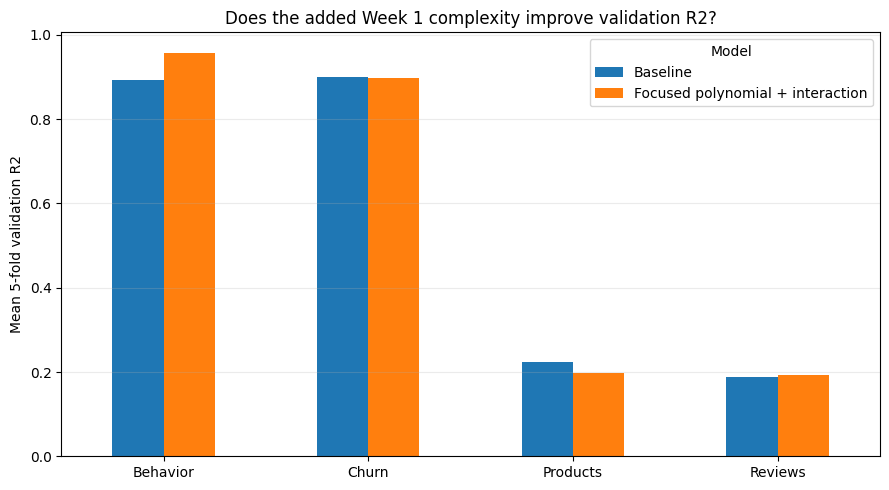

In [15]:
# Decision-oriented view: validation R2 across the four datasets.

validation_r2 = model_comparison.pivot(
    index="Dataset",
    columns="Model",
    values="Mean validation CV R2",
)

ax = validation_r2.plot(kind="bar", figsize=(9, 5))
ax.set_title("Does the added Week 1 complexity improve validation R2?")
ax.set_xlabel("")
ax.set_ylabel("Mean 5-fold validation R2")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### What changed after adding the nonlinear terms?

The answer is different by dataset, which is exactly why I did not want to treat the four tables as interchangeable.

- **Behavior:** validation R2 improves from about **0.894 to 0.958**. This is a meaningful gain, so the focused nonlinear specification is justified here.
- **Churn:** validation R2 stays essentially unchanged at about **0.899**. The extra terms add complexity without improving generalization, so I would keep the simpler baseline.
- **Products:** the held-out test R2 improves slightly, but mean cross-validation R2 actually becomes worse and more variable. With only 728 products, this is a warning against trusting the more flexible specification.
- **Reviews:** validation R2 improves modestly from about **0.188 to 0.194**, and the test result also improves. The gain is real but small, so I would treat the extra terms as exploratory rather than decisive.

This is one of the most useful Week 1 conclusions: the same modeling idea can be valuable in one part of the customer journey and unnecessary in another.

## 8. Multicollinearity and VIF

Polynomial and interaction terms are built from the original predictors, so they can become highly correlated with those predictors. This can make individual coefficients unstable even when overall predictions look reasonable.

I check this with VIF using a small interpretable design for each dataset. I calculate VIF twice:

1. using the raw variables before constructing the square and interaction
2. mean-centering the base variables first, then constructing the same square and interaction

Centering does not solve true redundancy between different predictors. It helps with the avoidable multicollinearity created by powers and products of variables that have nonzero means.

In [16]:
VIF_SPECS = {
    "Behavior": {
        "df": behavior,
        "base": ["Sales", "Discount", "Browsing Time (min)"],
        "square": "Sales",
        "interaction": ("Sales", "Discount"),
    },
    "Churn": {
        "df": churn,
        "base": ["Tenure", "OrderCount", "CouponUsed"],
        "square": "Tenure",
        "interaction": ("Tenure", "OrderCount"),
    },
    "Products": {
        "df": products,
        "base": ["price_value", "rating_stars_num", "recent_purchases_num"],
        "square": "price_value",
        "interaction": ("rating_stars_num", "recent_purchases_num"),
    },
    "Reviews": {
        "df": reviews,
        "base": ["rating", "review_len", "helpfulVoteCount"],
        "square": "rating",
        "interaction": ("rating", "review_len"),
    },
}


def calculate_vif(frame):
    clean = frame.replace([np.inf, -np.inf], np.nan).dropna()
    clean = clean.loc[:, clean.std(ddof=0) > 0]

    return pd.DataFrame(
        {
            "Feature": clean.columns,
            "VIF": [
                variance_inflation_factor(clean.values, i)
                for i in range(clean.shape[1])
            ],
        }
    ).sort_values("VIF", ascending=False)

In [17]:
vif_summary_rows = []
vif_details = {}

for name, spec in VIF_SPECS.items():
    base = spec["df"][spec["base"]].astype(float).dropna().copy()
    x1, x2 = spec["interaction"]

    raw = base.copy()
    raw[f"{spec['square']}^2"] = base[spec["square"]] ** 2
    raw[f"{x1} x {x2}"] = base[x1] * base[x2]

    centered = base - base.mean()
    centered_terms = centered.copy()
    centered_terms[f"{spec['square']}_c^2"] = centered[spec["square"]] ** 2
    centered_terms[f"{x1}_c x {x2}_c"] = centered[x1] * centered[x2]

    raw_vif = calculate_vif(raw)
    centered_vif = calculate_vif(centered_terms)

    vif_details[name] = {
        "raw": raw_vif,
        "centered": centered_vif,
    }

    vif_summary_rows.append(
        {
            "Dataset": name,
            "Raw max VIF": raw_vif["VIF"].max(),
            "Raw terms with VIF > 5": int((raw_vif["VIF"] > 5).sum()),
            "Centered max VIF": centered_vif["VIF"].max(),
            "Centered terms with VIF > 5": int(
                (centered_vif["VIF"] > 5).sum()
            ),
        }
    )

vif_summary = pd.DataFrame(vif_summary_rows)
display(vif_summary.round(3))

,Dataset,Raw max VIF,Raw terms with VIF > 5,Centered max VIF,Centered terms with VIF > 5
0,Behavior,75.1330,4,1.0160,0
1,Churn,11.0210,4,2.0440,0
2,Products,353.0700,5,2.5150,0
3,Reviews,114.4450,4,2.5710,0


In [18]:
# Show the full raw and centered VIF tables for one example, then the summary above
# provides the cross-dataset view.

print("Behavior - raw terms")
display(vif_details["Behavior"]["raw"])

print("Behavior - centered terms")
display(vif_details["Behavior"]["centered"])

Behavior - raw terms


,Feature,VIF
0,Sales,75.1326
3,Sales^2,65.3025
4,Sales x Discount,23.7013
1,Discount,21.4225
2,Browsing Time (min),4.0014


Behavior - centered terms


,Feature,VIF
3,Sales_c^2,1.0163
0,Sales,1.0163
4,Sales_c x Discount_c,1.0002
2,Browsing Time (min),1.0001
1,Discount,1.0001


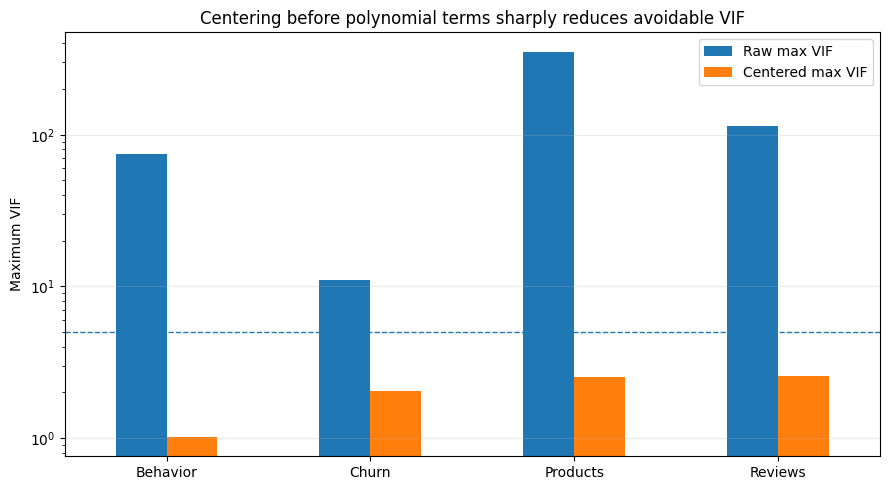

In [19]:
# Visual summary of the maximum VIF before and after centering.

vif_plot = vif_summary.set_index("Dataset")[
    ["Raw max VIF", "Centered max VIF"]
]

ax = vif_plot.plot(kind="bar", figsize=(9, 5))
ax.axhline(5, linestyle="--", linewidth=1)
ax.set_title("Centering before polynomial terms sharply reduces avoidable VIF")
ax.set_xlabel("")
ax.set_ylabel("Maximum VIF")
ax.set_yscale("log")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### VIF interpretation

The raw polynomial designs create very high VIFs in every table. The maximum raw VIF is especially large in the product and review examples. After centering, the maximum VIF falls below 3 in all four designs and no centered term exceeds the common warning threshold of 5.

That is a useful distinction. The original data are not suddenly "fixed" by centering. Instead, centering removes much of the artificial collinearity caused by multiplying or squaring variables around a nonzero mean.

For any coefficient-level interpretation of the nonlinear terms, I would use the centered specification.

## 9. Focused interaction interpretation

The interaction term asks whether the slope of one predictor changes as another predictor changes.

To make this less abstract, I fit one small centered interaction model for each table:

- profit as a function of sales and discount
- cashback amount as a function of order count and tenure
- log rating count as a function of rating and recent purchases
- sentiment as a function of rating and review length

These are intentionally simple models for interpretation. They are not meant to replace the fuller predictive models above.

In [20]:
INTERACTION_SPECS = {
    "Behavior": {
        "df": behavior,
        "target": "Profit",
        "x": "Sales",
        "moderator": "Discount",
    },
    "Churn": {
        "df": churn,
        "target": "CashbackAmount",
        "x": "OrderCount",
        "moderator": "Tenure",
    },
    "Products": {
        "df": products,
        "target": "log_rating_count",
        "x": "rating_stars_num",
        "moderator": "recent_purchases_num",
    },
    "Reviews": {
        "df": reviews,
        "target": "sentiment_score",
        "x": "rating",
        "moderator": "review_len",
    },
}

interaction_models = {}
interaction_rows = []

for name, spec in INTERACTION_SPECS.items():
    d = (
        spec["df"][[spec["target"], spec["x"], spec["moderator"]]]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .astype(float)
        .copy()
    )

    x_mean = d[spec["x"]].mean()
    moderator_mean = d[spec["moderator"]].mean()

    d["x_c"] = d[spec["x"]] - x_mean
    d["moderator_c"] = d[spec["moderator"]] - moderator_mean
    d["interaction"] = d["x_c"] * d["moderator_c"]

    model = LinearRegression().fit(
        d[["x_c", "moderator_c", "interaction"]],
        d[spec["target"]],
    )

    interaction_models[name] = {
        "model": model,
        "data": d,
        "x_mean": x_mean,
        "moderator_mean": moderator_mean,
        "spec": spec,
    }

    interaction_rows.append(
        {
            "Dataset": name,
            "Main X coefficient": model.coef_[0],
            "Moderator coefficient": model.coef_[1],
            "Interaction coefficient": model.coef_[2],
            "Illustrative R2": model.score(
                d[["x_c", "moderator_c", "interaction"]],
                d[spec["target"]],
            ),
        }
    )

interaction_table = pd.DataFrame(interaction_rows)
display(interaction_table.round(5))

,Dataset,Main X coefficient,Moderator coefficient,Interaction coefficient,Illustrative R2
0,Behavior,0.6874,-392.5018,-4.4713,0.8689
1,Churn,4.1566,2.5127,0.0413,0.2811
2,Products,2.0086,0.0007,-0.0004,0.1826
3,Reviews,0.0902,-0.0011,-0.0005,0.1896


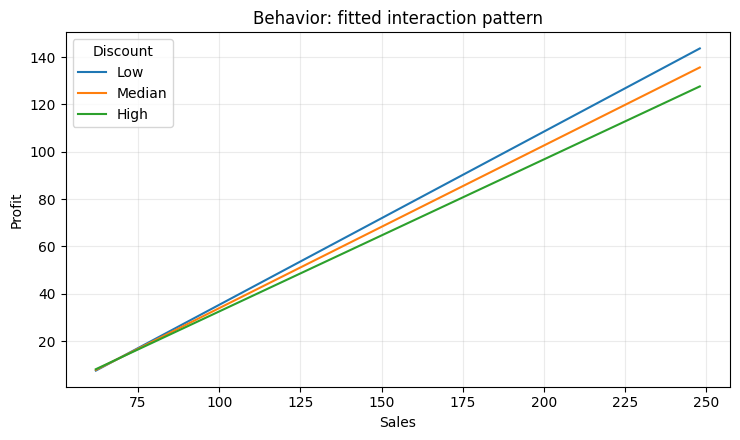

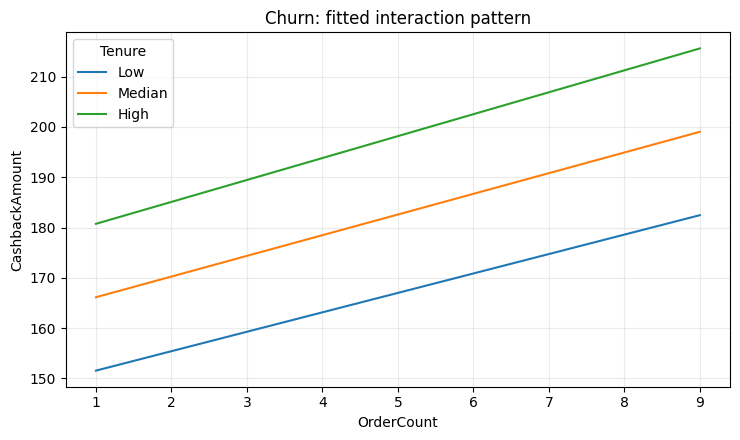

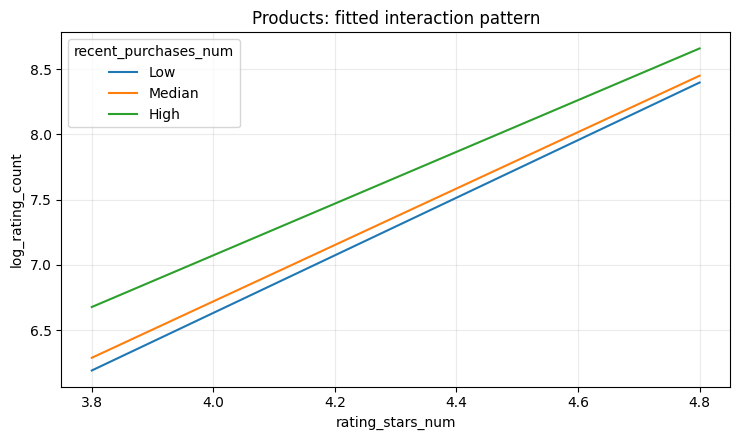

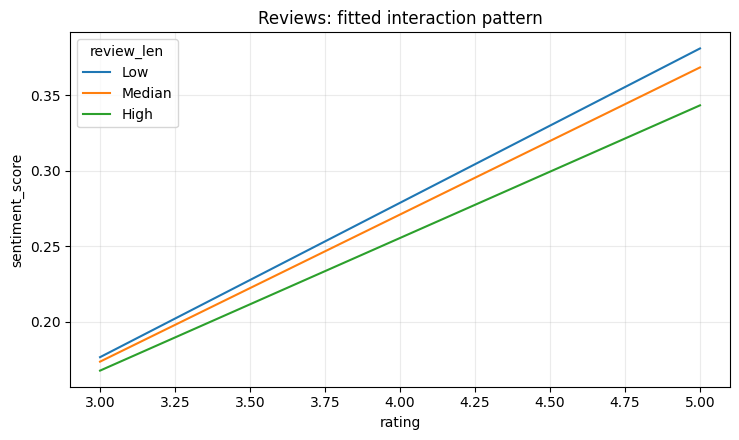

In [21]:
# Plot the fitted relationship at low, median, and high moderator levels.
# A separate figure is produced for each dataset so each one stays readable.

for name, info in interaction_models.items():
    model = info["model"]
    d = info["data"]
    spec = info["spec"]

    x_values = np.linspace(
        d[spec["x"]].quantile(0.05),
        d[spec["x"]].quantile(0.95),
        100,
    )

    moderator_levels = {
        "Low": d[spec["moderator"]].quantile(0.25),
        "Median": d[spec["moderator"]].median(),
        "High": d[spec["moderator"]].quantile(0.75),
    }

    fig, ax = plt.subplots(figsize=(7.5, 4.5))

    for level_name, moderator_value in moderator_levels.items():
        x_c = x_values - info["x_mean"]
        moderator_c = moderator_value - info["moderator_mean"]

        design = pd.DataFrame(
            {
                "x_c": x_c,
                "moderator_c": np.repeat(moderator_c, len(x_values)),
                "interaction": x_c * moderator_c,
            }
        )

        prediction = model.predict(design)
        ax.plot(x_values, prediction, label=level_name)

    ax.set_title(f"{name}: fitted interaction pattern")
    ax.set_xlabel(spec["x"])
    ax.set_ylabel(spec["target"])
    ax.legend(title=spec["moderator"])
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

### Interaction observations

The interaction plots make the Week 1 idea easier to interpret than a coefficient table alone.

- In **behavior**, discount clearly changes the profit relationship with sales. This matches the large improvement from the focused nonlinear model.
- In **churn**, the tenure interaction is small relative to the strong baseline model. That is consistent with the lack of cross-validation improvement.
- In **products**, the rating relationship changes somewhat with recent purchase activity, but the small sample and unstable validation performance make this more exploratory than conclusive.
- In **reviews**, the rating-sentiment relationship changes slightly with review length, but the overall linear model still explains only a modest share of sentiment variation.

I would not compare the raw interaction coefficients across datasets because the variables are on different scales.

## 10. Week 1 conclusions

### What I learned

1. **Polynomial and interaction terms helped most in the behavior data.** Validation R2 increased from roughly 0.894 to 0.958, so the extra terms captured real structure rather than only improving the training fit.
2. **More complexity was not automatically better.** The churn model gained essentially nothing from the added terms, and the product model became less stable under cross-validation.
3. **The review model improved only modestly.** That makes sense because the target is sentiment derived from review text, while this Week 1 model only uses structured metadata.
4. **Centering matters before coefficient interpretation.** Raw square and interaction terms produced high VIF values across all four tables. Centering reduced the avoidable multicollinearity substantially.
5. **Categorical features were handled as categories, not arbitrary numbers.** One-hot encoding allowed the linear models to combine customer, transaction, catalog, and review context without inventing numeric distance between labels.
6. **The four datasets contribute different evidence to one project.** Behavior is strongest for transaction economics, churn for customer-value patterns, products for catalog demand, and reviews for post-purchase experience.

### Model decision

For Week 1, I would carry the focused nonlinear behavior model forward as evidence that interactions matter for transaction economics. I would keep the simpler churn baseline, treat the product nonlinear result cautiously, and keep the review interaction as an exploratory finding rather than a final decision model.

This week also gives me a practical setup for later models: use held-out evaluation, preserve each table's grain, prevent entity leakage, and add complexity only when validation evidence supports it.

## 11. Sources and reproducibility notes

**Course materials**

- DX799 O1, Week 1: *Polynomial and Interaction Terms*
- DX799 O1, Week 1: *Jupyter Notebook - Linear Regression 1*
- Module C: *Milestone One Guidelines and Rubric*

**External references**

- scikit-learn developers. *LinearRegression*: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html
- scikit-learn developers. *OneHotEncoder*: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html
- statsmodels developers. *variance_inflation_factor*: https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html

These are primary software-library references for the exact tools used in the notebook.

**Reproducibility**

- Random seed: 42
- Test split: 20%
- Model selection evidence: five-fold cross-validation on the training data
- Group-aware splitting: `Customer ID` for behavior and `productASIN` for reviews
- All four cleaned datasets are used directly at their valid grains
